# Semana 7 · Importancia de variables, diagnósticos y matriz de consistencia

**Grupo 2 · Sistema de Tutoría Inteligente Adaptativa (DRL) para comprensión lectora**
Proyecto de Investigación 2 — Maestría en IA, UNI · Prof. Glen Rodríguez · rama `feat/variable-importance-and-consistency-matrix`

En este notebook justificamos con evidencia qué variables se quedan en el modelo (ablación por fold, importancias, SHAP, VIF y estabilidad entre folds), revisamos curvas de aprendizaje y calibración, y cerramos con la matriz de consistencia.

Todo se calcula a partir de los resultados guardados en `data/results/` (generados con `python -m src.run_ab`). No se vuelve a entrenar aquí.

## 1. Matriz de consistencia

| Problema | Objetivos | Hipótesis | Variables (Independientes y Dependientes) | Indicadores y Evidencia Experimental |
|---|---|---|---|---|
| **Problema General:**<br>¿En qué medida un Sistema de Tutoría Inteligente Adaptativa basado en *Deep Reinforcement Learning* (DRL), alimentado con una representación depurada de acoplamiento habilidad–dificultad, mejora la ganancia de aprendizaje en comprensión lectora frente a políticas de estado crudo sin depurar? | **Objetivo General (OG):**<br>Diseñar, implementar y validar un Sistema de Tutoría Inteligente Adaptativa basado en DRL (PPO / Dyna-PPO), integrando selección de variables sin colinealidad y calibración probabilística, para optimizar la secuencia de textos y maximizar la comprensión lectora. | **Hipótesis General (HG):**<br>El Sistema de Tutoría Inteligente basado en DRL con representación depurada (`Var2: clean5 + 2 vars ZPD`) incrementa significativamente la ganancia de aprendizaje normalizada ($LG_{\text{sim}}$) en estudiantes no vistos respecto al *Baseline* de estado crudo ($p < 0.05$). | **Variable Independiente General (VI):**<br>Representación de datos y política de secuenciación adaptativa DRL (`Baseline FS0_raw13` vs. `Var1 FS1_zpd4` vs. `Var2 D2_clean5_zpd2`).<br><br>**Variable Dependiente General (VD):**<br>Ganancia de aprendizaje en comprensión lectora (competencias literal $\theta_1$, inferencial $\theta_2$ y crítica $\theta_3$). | • **Ganancia de Aprendizaje Normalizada de Hake ($LG_{\text{sim}}$):**<br>$$LG_{\text{sim}} = \frac{\bar{\theta}_{\text{post}} - \bar{\theta}_{\text{pre}}}{1 - \bar{\theta}_{\text{pre}}}$$<br>• **Resultado en validación holdout (`GroupKFold`, 10 pares):**<br>  - `Baseline (FS0_raw13)`: $-0.0095 \pm 0.0174$<br>  - `Var1 (FS1_zpd4)`: $+0.0105 \pm 0.0150$<br>  - **`Var2 (D2_clean5_zpd2)`**: **$+0.0203 \pm 0.0167$**<br>• **Mejora pareada (`Var2 − Baseline`):** $\Delta LG = +0.0298$, IC95 $[+0.0225, +0.0372]$, $p_{\text{Holm}} = 0.008$, $d_z = 2.40$ (**gana en $10/10$ pares y $5/5$ folds**).<br>• **Eventos de aprendizaje por paso:** $0.334$ en `Var2` vs. $0.273$ en `Baseline`. |
| **Problema Específico 1 (Importancia de Variables, Colinealidad y Calibración):**<br>¿Cuáles son las variables de estado y de interacción alumno–texto que explican la transición de aprendizaje lector sin incurrir en colinealidad ni sesgo por ruido, y qué nivel de discriminación y calibración alcanzan? | **Objetivo Específico 1 (OE1):**<br>Identificar y justificar el subconjunto mínimo de variables mediante importancia en árboles (`Impurity Gain`), importancia por permutación en validación, valores `SHAP`, Factor de Inflación de Varianza (`VIF`) y curvas de calibración (`Brier Score`). | **Hipótesis Específica 1 (HE1):**<br>La poda de las 8 columnas sin señal del estado (5 constantes de varianza cero y 3 canales de ruido $\sigma_{1..3}$) junto con **2 variables de acoplamiento ZPD (`zpd_hit` y `abs_gap`)** mantiene $\text{VIF} < 2.5$, repite el Top-2 en el $100\%$ de los folds, alcanza $\text{ROC-AUC} \ge 0.85$ a nivel de ítem y reduce el `Brier Score` por debajo de $0.10$. | **var(s) indep(s):**<br>1. **`zpd_hit`**: proporción de ítems del texto dentro de la ventana de aprendizaje ($\lvert\theta_k - b_{adj}\rvert < 0.5$).<br>2. **`abs_gap`**: distancia absoluta entre habilidad del alumno y dificultad ajustada ($\lvert\theta_k - b_{adj}\rvert$).<br>3. **`clean5` (Estado limpio):** habilidades $\theta_1, \theta_2, \theta_3$, progreso de sesión $t/50$ y dificultad previa $b_{t-1}$.<br><br>**var depend:**<br>Probabilidad calibrada de transición de aprendizaje $P(\Delta\theta_k > 0 \mid s_t, a_t)$. | • **Importancia por Permutación ($\Delta\text{AUC}$ en validación, 5 folds):**<br>  - `zpd_hit`: **$0.0960$ (Puesto #1 en $5/5$ folds)**<br>  - `abs_gap`: **$0.0142$ (Puesto #2 en $5/5$ folds)**<br>  - Ruido $\sigma_{1..3}$: $\le 0.0015$ (frente a $16.4\%$ de ganancia espuria en `RandomForest` por impureza).<br>• **Explicabilidad `|SHAP|` medio en validación:** `zpd_hit` $= 0.0677$, `abs_gap` $= 0.0127$.<br>• **Control de colinealidad (`VIF`):** máximo **$2.12$** (reducido desde $4.04$ en `FS1_zpd4` y $\infty$ en `FS2_hist6`).<br>• **Discriminación (`ROC-AUC`, 5 folds):** **$0.9261$** (curva de aprendizaje, GBDT) y **$0.9479$** (modelo calibrado a nivel pregunta) vs. $0.4974$ del `Baseline`.<br>• **Calibración (`Brier Score` y `ECE`):** `Brier` $= \mathbf{0.0703 \pm 0.0028}$ ($-57.5\%$ vs. $0.1656$ del `Baseline`); `ECE` en pre-decisión por texto baja de $0.258$ a **$0.053$ ($-79.5\%$)**. |
| **Problema Específico 2 (Eficiencia Muestral y Seguridad Pedagógica CMDP):**<br>¿En qué medida la eliminación de los canales de ruido amplificados por el escalador y la reducción a 2 variables ZPD aceleran la convergencia del agente PPO sin vulnerar la restricción de frustración del alumno? | **Objetivo Específico 2 (OE2):**<br>Evaluar mediante curvas de aprendizaje (*Learning Curves* Train vs. Validación) el impacto de la depuración de datos sobre la velocidad de convergencia en episodios y sobre la tasa de activación del escudo de seguridad pedagógica (*CMDP shield*). | **Hipótesis Específica 2 (HE2):**<br>La variante depurada (`Var2: clean5 + 2 vars ZPD`) corrige el alto sesgo (*underfitting*) del `Baseline`, alcanza el desempeño final del `Baseline` en $\le 500$ episodios y mantiene la tasa de activación del escudo de frustración en $\le 0.02$ por paso. | **var(s) indep(s):**<br>Acondicionamiento de la matriz de estado-acción (eliminación del factor de amplificación de ruido de $34.6\times$ sobre $\sigma_{1..3}$ en `StandardScaler`).<br><br>**var depend:**<br>1. Episodios de entrenamiento requeridos hasta convergencia.<br>2. Tasa de violaciones de seguridad (rachas de $\ge 4$ errores consecutivos). | • **Episodios hasta alcanzar el $LG$ final del Baseline (mediana de 10 pares):**<br>  - `Baseline`: $750$ episodios<br>  - `Var1 (4 vars ZPD)`: $350$ episodios<br>  - **`Var2 (clean5 + 2 vars ZPD)`**: **$275$ episodios** ($-63.3\%$ respecto al `Baseline`, cumpliendo $\le 500$).<br>• **Brecha de generalización (Train vs. Validación):** curvas de entrenamiento y validación ascienden juntas sin sobreajuste ($\Delta_{\text{train-val}} < 1\text{ EE}$).<br>• **Tasa de activación del escudo CMDP (`shield_holdout`):** **$0.017$ por paso** (idéntica al `Baseline` $0.017$, sin incremento de frustración). |
| **Problema Específico 3 (Complejidad Computacional y Robustez sin Oráculo):**<br>¿Cuál es el efecto de la poda de variables sobre el costo computacional de inferencia y sobre la ganancia de aprendizaje cuando la habilidad real $\theta^*$ no es observable y debe estimarse en línea a partir de respuestas dicotómicas? | **Objetivo Específico 3 (OE3):**<br>Cuantificar la reducción de parámetros, la latencia por decisión y la estabilidad del *Learning Gain* al sustituir el oráculo $\theta^*$ por un estimador recursivo Elo ($\hat{\theta}_k$) y establecer el protocolo de transición a aula real. | **Hipótesis Específica 3 (HE3):**<br>El modelo depurado (`Var2`) reduce en más del $50\%$ los parámetros entrenables de la política, mantiene una latencia $< 1\text{ ms}$ por paso y preserva una ganancia superior al `Baseline` y a `Var1` bajo habilidad estimada $\hat{\theta}$. | **var(s) indep(s):**<br>1. Dimensión del vector de entrada $(d_s=5, d_a=2)$ frente a $(13, 4)$.<br>2. Régimen de observación de habilidad: $\theta^*$ verdadera vs. $\hat{\theta}$ estimada con Elo online ($K=0.1$).<br><br>**var depend:**<br>1. Número de parámetros y latencia de inferencia (ms).<br>2. $LG_{\text{sim}}$ bajo habilidad observable $\hat{\theta}$. | • **Parámetros entrenables de la política:** **$542$ parámetros** en `Var2` frente a $1\,264$ en `Var1` y $1\,260$ en `Baseline` (**$-57.1\%$ de parámetros**).<br>• **Latencia mediana de decisión:** **$0.118\text{ ms}$** ($p_{95} = 0.21\text{ ms}$; $-21.3\%$ más rápida que `Var1` con $0.150\text{ ms}$).<br>• **Desempeño sin oráculo ($\hat{\theta}$ Elo online en test):** `Var2` alcanza $LG = +0.0009$ frente a $-0.0006$ de `Var1` y $-0.0101$ del `Baseline` ($\Delta LG = +0.0110$, ganando en $4/5$ folds). |

## 2. Preparación y control de fuga de información

Primero cargamos los resultados y corremos las 5 pruebas automáticas de *leakage* (split por alumno, escalador ajustado solo con train, etc.).

In [1]:
import os, sys, json, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# En Colab se clona el repo; en local se usa la carpeta del proyecto
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    os.system("git clone -b feat/variable-importance-and-consistency-matrix https://github.com/yasminum/SistemaTutorInteligente.git repo")
    os.chdir("repo")

ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src import leakage_checks, report

s2 = json.loads((ROOT / "data/results/sprint2_diagnostics.json").read_text(encoding="utf-8"))
_, runs = report.load_runs(str(ROOT), "oracle")

NOMBRE = {
    "zpd_hit": "zpd_hit (proporción en zona de aprendizaje)",
    "abs_gap": "abs_gap (diferencia habilidad - dificultad)",
    "zpd_prox": "zpd_prox (cercanía gaussiana)",
    "p_hat": "p_hat (prob. de acierto 3PL)",
    "theta_1": "theta_1 (habilidad literal)",
    "theta_2": "theta_2 (habilidad inferencial)",
    "theta_3": "theta_3 (habilidad crítica)",
    "u_progress": "u_progress (avance de sesión t/50)",
    "b_prev_raw": "b_prev_raw (dificultad texto anterior)",
    "sigma_1": "sigma_1 (ruido del simulador)",
    "sigma_2": "sigma_2 (ruido del simulador)",
    "sigma_3": "sigma_3 (ruido del simulador)",
    "roll_acc_w5": "roll_acc_w5 (acierto últimos 5)",
    "ewma_err": "ewma_err (media móvil de error)",
    "err_streak": "err_streak (racha de errores)",
}

pd.DataFrame(leakage_checks.run_all_checks())

prueba,resultado,evidencia
L1 GroupKFold por estudiante,PASS,5 folds; interseccion train/test = 0; test cubre los 100 ids una vez
L2 Causalidad temporal,PASS,200 pruebas aleatorias: features(t) invariantes ante cambios en y_t..y_H
L3 Sin espiar el item actual,PASS,features calculadas antes de muestrear el item; cambiar el item de t no altera Phi(t)
L4 Scaler fit solo en train,PASS,scaler ajustado con 18 ids distintos muestreados de train; 0 ids de test
L5 Politica congelada en test,PASS,pesos identicos antes/despues de evaluar en test (sin aprendizaje en test)


## 3. Datos coherentes (checklist de la semana)

Revisamos tipos, rangos y nulos del banco de preguntas que usa el simulador.

In [2]:
bank = pd.read_csv(ROOT / "data/item_bank.csv")
print("Filas:", len(bank), "| Nulos totales:", int(bank.isna().sum().sum()))
pd.DataFrame({
    "columna": bank.columns,
    "tipo": bank.dtypes.astype(str).values,
    "mínimo": [bank[c].min() for c in bank.columns],
    "máximo": [bank[c].max() for c in bank.columns],
    "nulos": bank.isna().sum().values,
})

Filas: 300 | Nulos totales: 0


columna,tipo,mínimo,máximo,nulos
text_id,int64,0.000000,29.000000,0
item_id,int64,0.000000,9.000000,0
a,float64,0.802163,1.999324,0
b,float64,-3.111422,3.236232,0
c,float64,0.250000,0.250000,0
skill_k,int64,0.000000,2.000000,0


## 4. Colinealidad (VIF)

En la Variante 1 metimos 4 variables ZPD que miden casi lo mismo (la distancia entre la habilidad del alumno y la dificultad). El VIF lo confirma. Al quedarnos solo con `zpd_hit` y `abs_gap`, el VIF máximo baja a ~2.1.

In [3]:
vif4 = s2["vif"]["zpd4_4vars"]
vif_final = s2["vif"]["clean5_zpd2"]
filas = []
for v in ["zpd_hit", "zpd_prox", "abs_gap", "p_hat", "theta_1", "theta_2", "theta_3", "u_progress", "b_prev_raw"]:
    filas.append({
        "Variable": NOMBRE[v],
        "VIF Variante 1 (4 vars ZPD)": round(vif4[v], 2) if v in vif4 else "—",
        "VIF Variante 2 (modelo final)": round(vif_final[v], 2) if v in vif_final else "eliminada",
    })
pd.DataFrame(filas)

Variable,VIF Variante 1 (4 vars ZPD),VIF Variante 2 (modelo final)
zpd_hit (proporción en zona de aprendizaje),4.04,2.07
zpd_prox (cercanía gaussiana),3.84,eliminada
abs_gap (diferencia habilidad - dificultad),2.6,2.12
p_hat (prob. de acierto 3PL),1.42,eliminada
theta_1 (habilidad literal),—,1.01
theta_2 (habilidad inferencial),—,1.01
theta_3 (habilidad crítica),—,1.03
u_progress (avance de sesión t/50),—,1.0
b_prev_raw (dificultad texto anterior),—,1.0


## 5. Importancia de variables: árboles vs. permutación vs. SHAP

Seguimos el esquema visto en clase: `RandomForestClassifier(n_estimators=300, random_state=42)` ajustado solo con el train de cada fold, y `feature_importances_` ordenado. Como la importancia por impureza puede engañar con variables continuas de ruido, la contrastamos con la importancia por permutación (caída de ROC-AUC al barajar la variable en validación) y con SHAP en validación.

In [4]:
rf = pd.DataFrame(s2["importances"]["rf_gain_15vars"])
perm = pd.DataFrame(s2["importances"]["perm_auc_15vars"])
shap_m = s2["shap"]["mean_abs_shap"]

importancias = rf.mean(axis=1).sort_values(ascending=False)
print("Importancia por impureza (media de 5 folds):")
print(importancias.head(10).round(4))

def decision(v):
    if v in ("zpd_hit", "abs_gap"): return "Se queda (top-2 en permutación)"
    if v in ("theta_1", "theta_2", "theta_3", "u_progress", "b_prev_raw"): return "Se queda (estado limpio)"
    if v.startswith("sigma"): return "Sale (ruido del simulador)"
    if v == "zpd_prox": return "Sale (redundante con zpd_hit)"
    return "Sale (no aporta en validación)"

tabla = pd.DataFrame({
    "Variable": [NOMBRE.get(v, v) for v in importancias.index],
    "Importancia árboles": importancias.round(4).values,
    "Importancia permutación (validación)": perm.mean(axis=1).loc[importancias.index].round(4).values,
    "|SHAP| medio": [round(shap_m[v], 4) if v in shap_m else "—" for v in importancias.index],
    "Decisión": [decision(v) for v in importancias.index],
})
tabla

Importancia por impureza (media de 5 folds):
zpd_hit     0.1713
zpd_prox    0.1388
abs_gap     0.1072
p_hat       0.0733
theta_3     0.0683
theta_1     0.0561
sigma_3     0.0556
sigma_2     0.0552
theta_2     0.0534
sigma_1     0.0532
dtype: float64


Variable,Importancia árboles,Importancia permutación (validación),|SHAP| medio,Decisión
zpd_hit (proporción en zona de aprendizaje),0.1713,0.0791,0.0677,Se queda (top-2 en permutación)
zpd_prox (cercanía gaussiana),0.1388,0.0103,—,Sale (redundante con zpd_hit)
abs_gap (diferencia habilidad - dificultad),0.1072,0.0065,0.0127,Se queda (top-2 en permutación)
p_hat (prob. de acierto 3PL),0.0733,0.0011,—,Sale (no aporta en validación)
theta_3 (habilidad crítica),0.0683,0.0046,0.0148,Se queda (estado limpio)
theta_1 (habilidad literal),0.0561,-0.0002,0.0153,Se queda (estado limpio)
sigma_3 (ruido del simulador),0.0556,0.0012,—,Sale (ruido del simulador)
sigma_2 (ruido del simulador),0.0552,0.0002,—,Sale (ruido del simulador)
theta_2 (habilidad inferencial),0.0534,-0.0008,0.0043,Se queda (estado limpio)
sigma_1 (ruido del simulador),0.0532,-0.0004,—,Sale (ruido del simulador)


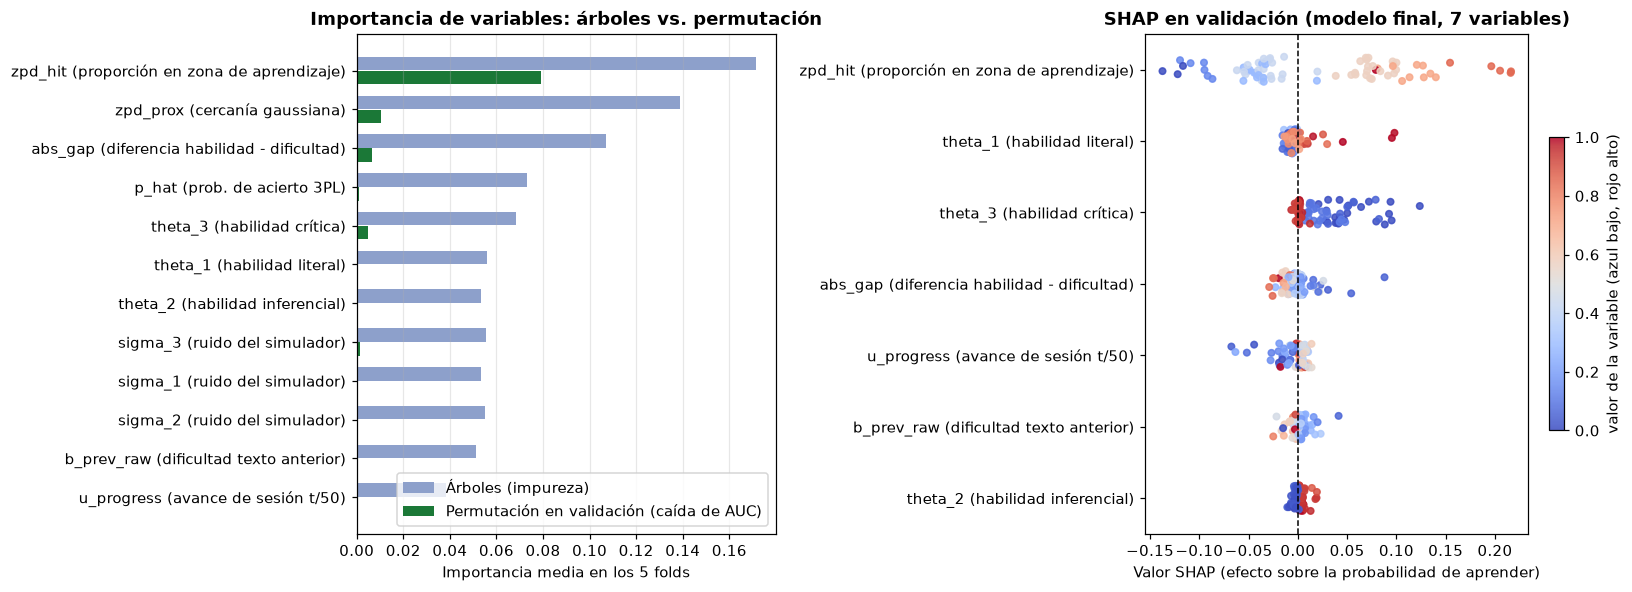

In [5]:
orden = ["zpd_hit", "zpd_prox", "abs_gap", "p_hat", "theta_3", "theta_1", "theta_2",
         "sigma_3", "sigma_1", "sigma_2", "b_prev_raw", "u_progress"][::-1]
y = np.arange(len(orden))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5))
a1.barh(y + 0.18, [rf.mean(axis=1)[v] for v in orden], 0.35, color="#8da0cb", label="Árboles (impureza)")
a1.barh(y - 0.18, [max(0, perm.mean(axis=1)[v]) for v in orden], 0.35, color="#1b7837", label="Permutación en validación (caída de AUC)")
a1.set_yticks(y); a1.set_yticklabels([NOMBRE[v] for v in orden])
a1.set_xlabel("Importancia media en los 5 folds")
a1.set_title("Importancia de variables: árboles vs. permutación", fontweight="bold")
a1.legend(loc="lower right"); a1.grid(axis="x", alpha=0.3)

nombres = s2["shap"]["feature_names"]
sv = np.array(s2["shap"]["shap_values_sample"]); fv = np.array(s2["shap"]["feature_values_sample"])
media = np.array([shap_m[k] for k in nombres]); ordb = np.argsort(media)
rng = np.random.default_rng(7)
for i, j in enumerate(ordb):
    col = (fv[:, j] - fv[:, j].min()) / (np.ptp(fv[:, j]) + 1e-12)
    sc = a2.scatter(sv[:, j], i + rng.uniform(-0.18, 0.18, len(sv)), c=col, cmap="coolwarm", s=18, alpha=0.85)
a2.axvline(0, color="k", ls="--", lw=1)
a2.set_yticks(range(len(nombres))); a2.set_yticklabels([NOMBRE[nombres[j]] for j in ordb])
a2.set_xlabel("Valor SHAP (efecto sobre la probabilidad de aprender)")
a2.set_title("SHAP en validación (modelo final, 7 variables)", fontweight="bold")
plt.colorbar(sc, ax=a2, fraction=0.035).set_label("valor de la variable (azul bajo, rojo alto)")
plt.tight_layout(); plt.show()

**Qué leemos aquí:**
- Las tres columnas `sigma_1..3` suman ~16 % de importancia en los árboles, pero al barajarlas en validación el AUC casi no cambia (≤ 0.0015). Es ruido del simulador que el árbol usa para partir datos de train; por eso salen.
- `zpd_hit` es la variable que más pesa en los tres métodos. En SHAP, valores altos (rojo) empujan la probabilidad de aprender hacia arriba.
- `abs_gap` es la #2 en permutación. En SHAP queda cuarta (|SHAP| = 0.013, muy cerca de `theta_1` y `theta_3`), porque buena parte de su información ya la recoge `zpd_hit`.

## 6. Estabilidad entre folds (¿se repite el top?)

In [6]:
pm7 = pd.DataFrame(s2["importances"]["perm_auc_pruned7"])
rank = pm7.rank(ascending=False, axis=0).astype(int)
estab = pd.DataFrame({
    "Variable": [NOMBRE[v] for v in pm7.index],
    "Puesto en Fold 0..4": [", ".join(f"#{r}" for r in rank.loc[v]) for v in pm7.index],
    "Permutación media": pm7.mean(axis=1).round(4).values,
    "VIF final": [round(vif_final[v], 2) for v in pm7.index],
}).sort_values("Permutación media", ascending=False)
estab

Variable,Puesto en Fold 0..4,Permutación media,VIF final
zpd_hit (proporción en zona de aprendizaje),"#1, #1, #1, #1, #1",0.0959,2.07
abs_gap (diferencia habilidad - dificultad),"#2, #2, #2, #2, #2",0.0140,2.12
theta_3 (habilidad crítica),"#3, #3, #3, #4, #4",0.0047,1.03
theta_1 (habilidad literal),"#7, #4, #4, #6, #7",-0.0002,1.01
b_prev_raw (dificultad texto anterior),"#4, #6, #6, #3, #6",-0.0003,1.00
u_progress (avance de sesión t/50),"#6, #5, #7, #5, #3",-0.0011,1.00
theta_2 (habilidad inferencial),"#5, #7, #5, #7, #5",-0.0025,1.01


`zpd_hit` sale #1 y `abs_gap` #2 en los 5 folds. Del puesto 3 en adelante el orden cambia de fold a fold, lo cual es esperable porque esas importancias son casi cero.

## 7. Curvas de aprendizaje y calibración

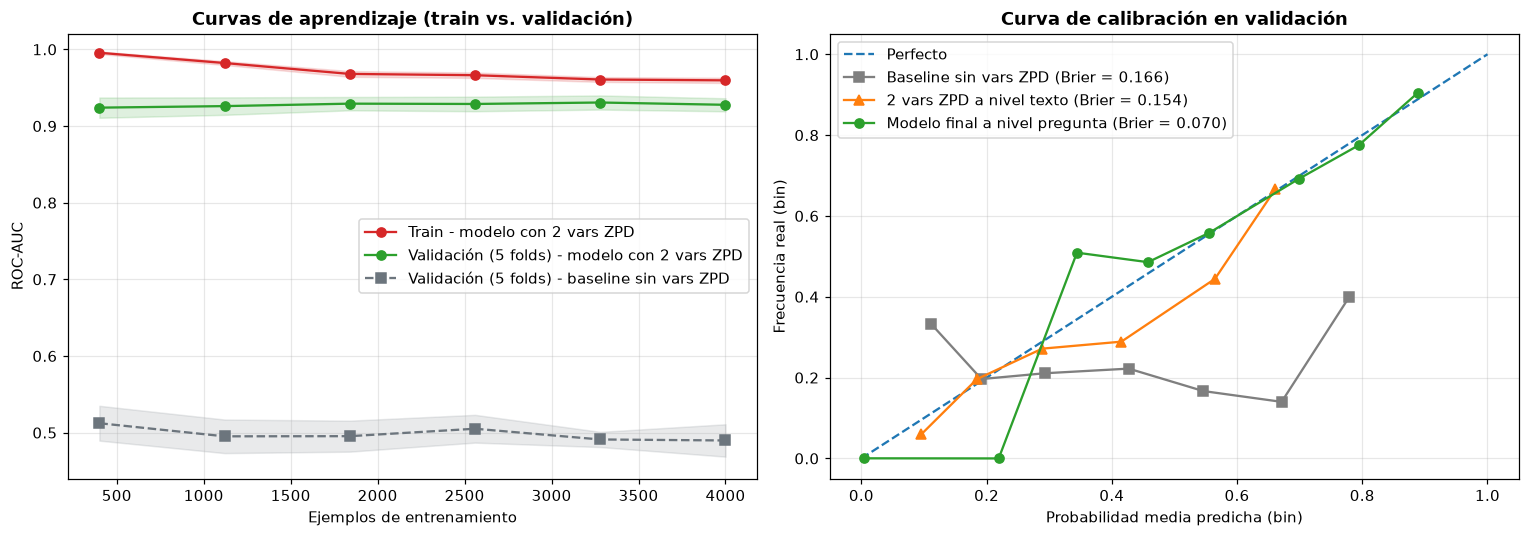

Modelo,Brier (menor es mejor),ROC-AUC validación,Log-loss,ECE
Baseline (FS0_raw13),0.1656 ± 0.0096,0.4974 ± 0.0178,0.5136,0.2577
FS2_hist6 (Historial sin ZPD),0.1690 ± 0.0108,0.5003 ± 0.0240,0.5215,0.2757
Pre-decisión Texto (D2: clean5 + 2 vars ZPD),0.1544 ± 0.0103,0.6352 ± 0.0127,0.4812,0.0528
Modelo Transición Ítem (D2: clean5 + 2 vars ZPD),0.0703 ± 0.0028,0.9479 ± 0.0049,0.2040,0.0576


In [7]:
lc = s2["learning_curves_supervised"]
fin = lc["Modelo de Mundo Ítem (clean5 + 2 vars ZPD ítem)"]; base = lc["Baseline (FS0_raw13)"]
n = np.array(fin["train_sizes"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
for d, lab, c, mk in [(fin, "Train - modelo con 2 vars ZPD", "#d62728", "train"),
                      (fin, "Validación (5 folds) - modelo con 2 vars ZPD", "#2ca02c", "val"),
                      (base, "Validación (5 folds) - baseline sin vars ZPD", "#6c757d", "val")]:
    m, s = np.array(d[f"{mk}_mean"]), np.array(d[f"{mk}_std"])
    a1.plot(n, m, "o-" if "baseline" not in lab else "s--", color=c, label=lab)
    a1.fill_between(n, m - s, m + s, color=c, alpha=0.15)
a1.set_xlabel("Ejemplos de entrenamiento"); a1.set_ylabel("ROC-AUC")
a1.set_title("Curvas de aprendizaje (train vs. validación)", fontweight="bold")
a1.set_ylim(0.44, 1.02); a1.grid(alpha=0.3); a1.legend(loc="center right")

cal = s2["calibration"]
a2.plot([0, 1], [0, 1], "--", color="#1f77b4", label="Perfecto")
for k, lab, c, mk in [("Baseline (FS0_raw13)", "Baseline sin vars ZPD", "#7f7f7f", "s-"),
                      ("Pre-decisión Texto (D2: clean5 + 2 vars ZPD)", "2 vars ZPD a nivel texto", "#ff7f0e", "^-"),
                      ("Modelo Transición Ítem (D2: clean5 + 2 vars ZPD)", "Modelo final a nivel pregunta", "#2ca02c", "o-")]:
    a2.plot(cal[k]["mean_pred"], cal[k]["frac_pos"], mk, color=c, label=f"{lab} (Brier = {cal[k]['brier_mean']:.3f})")
a2.set_xlabel("Probabilidad media predicha (bin)"); a2.set_ylabel("Frecuencia real (bin)")
a2.set_title("Curva de calibración en validación", fontweight="bold")
a2.grid(alpha=0.3); a2.legend(loc="upper left")
plt.tight_layout(); plt.show()

pd.DataFrame([{
    "Modelo": k,
    "Brier (menor es mejor)": f"{v['brier_mean']:.4f} ± {v['brier_std']:.4f}",
    "ROC-AUC validación": f"{v['auc_mean']:.4f} ± {v['auc_std']:.4f}",
    "Log-loss": round(v["logloss_mean"], 4),
    "ECE": round(v["ece"], 4),
} for k, v in cal.items()])

**Conclusión breve:**
- **Baseline:** train y validación quedan pegadas en AUC ≈ 0.50 y no mejoran con más datos → alto *bias* (subajuste). Más datos no lo arreglan; hacía falta mejores variables, y eso es justamente lo que aportan `zpd_hit` y `abs_gap`.
- **Modelo con 2 vars ZPD:** validación estable en ≈ 0.93 desde ~1 000 ejemplos y brecha con train de ~0.03 → no hay sobreajuste importante y la curva ya se aplanó.
- **Calibración:** el Brier baja de 0.166 a 0.070. Los bins por debajo de 0.25 tienen pocos casos y por eso la curva salta ahí.

## 8. Ablación por fold: Baseline vs. Variante 1 vs. Variante 2

Mismo protocolo para todas: 100 alumnos simulados, `GroupKFold` de 5 folds (80 train / 20 validación) × 2 semillas = 10 corridas pareadas, 1 500 episodios cada una.

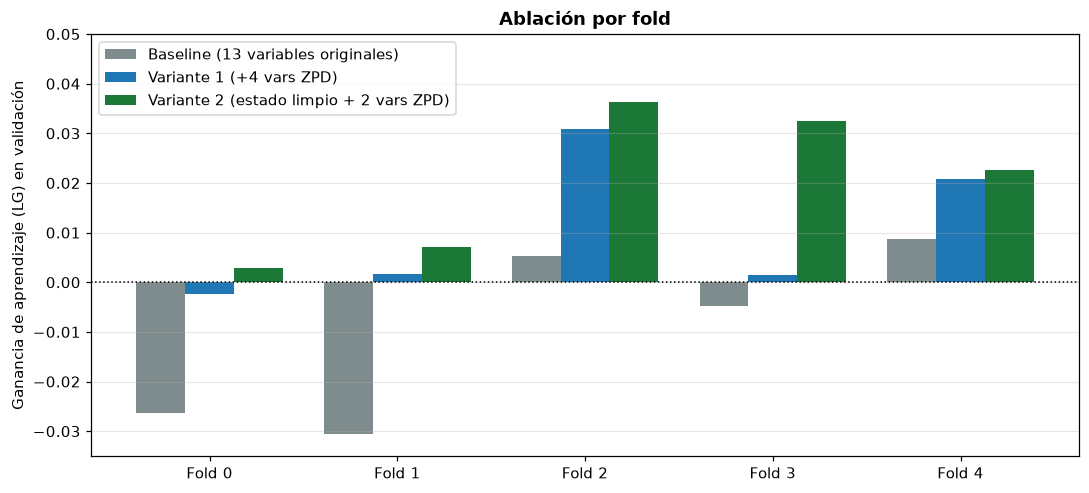

Fold,Baseline,Historial,Variante 1,2 vars ZPD (estado crudo),Variante 2,Mejora V1 sobre Baseline,Mejora V2 sobre Baseline,Mejora V2 sobre V1
Fold 0,-0.0263,-0.0066,-0.0024,0.0053,0.0028,0.0238,0.0291,0.0052
Fold 1,-0.0305,-0.0302,0.0017,-0.0084,0.0072,0.0322,0.0376,0.0054
Fold 2,0.0054,0.0050,0.0308,0.0240,0.0364,0.0254,0.0310,0.0056
Fold 3,-0.0048,0.0020,0.0014,0.0068,0.0324,0.0063,0.0372,0.0310
Fold 4,0.0087,-0.0015,0.0209,0.0193,0.0227,0.0122,0.0140,0.0018


In [8]:
fb = pd.DataFrame(s2["fold_by_fold"])
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(5); w = 0.26
for off, col, lab, c in [(-w, "PPOlin_FS0_raw13", "Baseline (13 variables originales)", "#7f8c8d"),
                         (0, "PPOlin_FS1_zpd4", "Variante 1 (+4 vars ZPD)", "#1f77b4"),
                         (w, "PPOlin_D2_clean5_zpd2", "Variante 2 (estado limpio + 2 vars ZPD)", "#1b7837")]:
    ax.bar(x + off, fb[col], w, color=c, label=lab)
ax.axhline(0, color="k", ls=":", lw=1)
ax.set_xticks(x); ax.set_xticklabels(fb["Fold"])
ax.set_ylabel("Ganancia de aprendizaje (LG) en validación")
ax.set_title("Ablación por fold", fontweight="bold")
ax.set_ylim(-0.035, 0.05); ax.legend(loc="upper left"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

fb.round(4).rename(columns={
    "PPOlin_FS0_raw13": "Baseline", "PPOlin_FS2_hist6": "Historial", "PPOlin_FS1_zpd4": "Variante 1",
    "PPOlin_D1_zpd2": "2 vars ZPD (estado crudo)", "PPOlin_D2_clean5_zpd2": "Variante 2",
    "dLG_Var1_zpd4_vs_Base": "Mejora V1 sobre Baseline", "dLG_Var2_D2_vs_Base": "Mejora V2 sobre Baseline",
    "dLG_Var2_D2_vs_Var1": "Mejora V2 sobre V1"})

Comparación pareada (misma partición y misma semilla). El p-valor sale de una prueba de permutación exacta y se corrige con Holm por las 4 comparaciones contra el baseline.

In [9]:
st = report.stats_table(runs)
st_v = st.rename(columns={"mean_diff": "Mejora media en LG", "ci_low": "IC95 inf", "ci_high": "IC95 sup",
                          "p_perm": "p (permutación)", "d_z": "d_z", "wins": "Corridas ganadas", "n": "Corridas"})
st_v.round(4)

Comparación,Mejora media en LG,IC95 inf,IC95 sup,p (permutación),d_z,Corridas ganadas,Corridas,p_Holm
PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,0.0200,0.0130,0.0274,0.0020,1.6096,10,10,0.0078
PPOlin_D1_zpd2 vs PPOlin_FS0_raw13,0.0189,0.0107,0.0278,0.0039,1.3035,9,10,0.0078
PPOlin_D2_clean5_zpd2 vs PPOlin_FS0_raw13,0.0298,0.0225,0.0372,0.0020,2.3985,10,10,0.0078
PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,0.0032,-0.0051,0.0122,0.4941,0.2210,5,10,0.4941


In [10]:
report.results_table(runs)

ID experimento,Variante,LG_sim holdout,Acierto,Eventos de aprendizaje/paso,Violaciones (shield)/paso,Costo CMDP/paso,Retorno,Episodios a LG_base (mediana),Pares que alcanzan,Ruta log,Nota (qué cambió)
FE5-PPOlin_FS0_raw13-oracle-f*-s*,PPOlin_FS0_raw13,-0.0095 ± 0.0174,0.730,0.273,0.017,0.032,15.040,750,10/10,logs/metrics_experimentos.csv,"Baseline: 13 rasgos crudos x_t de environment.py (incluye 5 constantes SD=0 y 3 ruidos U(0.05,0.15))"
FE5-PPOlin_FS1_zpd4-oracle-f*-s*,PPOlin_FS1_zpd4,+0.0105 ± 0.0150,0.716,0.312,0.016,0.041,15.489,350,10/10,logs/metrics_experimentos.csv,"Var1: Estado crudo (13) + 4 rasgos ZPD por accion (p_hat, abs_gap, zpd_prox, zpd_hit; VIF=3.96)"
FE5-PPOlin_D1_zpd2-oracle-f*-s*,PPOlin_D1_zpd2,+0.0094 ± 0.0159,0.707,0.313,0.022,0.039,15.282,325,10/10,logs/metrics_experimentos.csv,"Ablacion ZPD-2: Estado crudo (13) + solo 2 rasgos ZPD seleccionados por SHAP/Perm (abs_gap, zpd_hit)"
FE5-PPOlin_D2_clean5_zpd2-oracle-f*-s*,PPOlin_D2_clean5_zpd2,+0.0203 ± 0.0167,0.711,0.334,0.017,0.078,15.202,275,10/10,logs/metrics_experimentos.csv,"Var2 (Adoptada): Poda de 8 columnas muertas/ruido del estado (13->5) + 2 rasgos ZPD (abs_gap, zpd_hit)"
FE5-PPOlin_FS2_hist6-oracle-f*-s*,PPOlin_FS2_hist6,-0.0063 ± 0.0162,0.737,0.272,0.015,0.026,15.050,775,8/10,logs/metrics_experimentos.csv,"Var Historial: Estado crudo (13) + 6 rasgos temporales causales (acc_w5, racha, EWMA, nivel t-1)"


## 9. Hallazgos y decisión

1. **El baseline no podía aprender por cómo venían los datos, no por el algoritmo.** De sus 13 variables, 5 son constantes y 3 son ruido del simulador. Al escalarlas, ese ruido queda con el mismo peso que las variables útiles.
2. **La señal está en el cruce entre la habilidad del alumno y la dificultad del texto.** `zpd_hit` y `abs_gap` capturan eso; con ellas el AUC pasa de 0.50 a 0.93 y la ganancia de aprendizaje pasa de negativa a positiva en los 5 folds.

**Criterio de adopción:**

| Criterio | Variante 2 |
|---|---|
| Mejora consistente de la métrica central | LG +0.0203 vs −0.0095 del baseline; gana en 10/10 corridas y en 5/5 folds (p Holm = 0.008) |
| Colinealidad bajo control | VIF máximo 2.12 (Variante 1: 4.04) |
| Sin leakage | 5/5 pruebas automáticas, SHAP y permutación solo en validación |
| Costo | 542 parámetros (vs 1 264) y 0.12 ms por decisión |

**Limitaciones:** frente a la Variante 1 la mejora es de +0.0098 y gana 8 de 10 corridas, pero no llega a ser significativa (p = 0.06); la elegimos porque logra eso con menos de la mitad de parámetros y sin colinealidad. Además, todo se mide sobre alumnos simulados; falta validarlo con estudiantes reales.

**Para reproducir:** `pip install -r requirements.txt`, luego `python -m src.leakage_checks` y `python -m src.run_ab --variant PPOlin_D2_clean5_zpd2`.